# Exploratory Data Analysis and LSTM-Based Time-Series Forecasting
## Notebook 02: Exploratory Data Analysis (EDA) and Leakage-Free Preprocessing

**Project Title:** Exploratory Data Analysis and LSTM-Based Time-Series Forecasting Using Multivariate and Univariate Data  
**Dataset:** Beijing PM2.5 Air Quality and Meteorological Time Series  
**Level:** College / Academic Case Study  
**Deliverable:** 02_eda_and_preprocessing.ipynb  

---

### Aim and Objectives
1. **Time-Series Pattern Analysis:** Investigate longitudinal trends, diurnal cycles, annual seasonality, and episodic spikes in PM2.5 air pollution.
2. **Distributional & Outlier Exploration:** Quantify the probability distribution of particulate concentration, assess extreme values, and formulate a domain-justified outlier policy.
3. **Multivariate Meteorological Correlation:** Evaluate linear and non-linear associations between air pollution, wind speed, wind direction, humidity (dew point), temperature, barometric pressure, and precipitation.
4. **Leakage-Free Chronological Data Partitioning:** Implement strict temporal partitioning into Training (70%), Validation (15%), and Testing (15%) subsets without random shuffling.
5. **Preprocessing & Normalization:** Handle categorical wind direction features and fit feature/target `MinMaxScaler` transformations strictly on the training subset to prevent data leakage.


### 1. Theoretical Background & Data Science Concepts

#### The Principle of Zero Data Leakage in Time Series
In conventional cross-sectional machine learning, random shuffling and k-fold cross-validation are standard practices. In time-series forecasting, however, observations are chronologically ordered and temporally correlated. 
- **Data Leakage Hazard:** If an input scaler or transformer is fitted on the entire dataset prior to splitting, statistics from the future (such as the global maximum or mean of test periods) leak into the training representations. This produces artificially optimistic validation scores that fail to generalize to real-world forward testing.
- **Chronological Rule:** All preprocessing parameters (e.g., min and max scaling bounds, encoding maps) must be derived **solely from the training partition** $\mathcal{D}_{train} = \{x_1, \dots, x_{N_{train}}\}$, and subsequently applied without alteration to validation and testing partitions.

#### Atmospheric Dynamics and Air Pollution
Air particulate concentrations (PM2.5) are heavily dictated by atmospheric physics:
- **Wind Speed:** High wind speeds induce mechanical turbulence and advection, ventilating particulates away from the surface boundary layer.
- **Thermal Inversion:** In winter, surface radiative cooling can produce temperature inversions where cool surface air is trapped beneath warm aloft air, preventing vertical dispersion and causing catastrophic smog accumulation.
- **Humidity & Dew Point:** High dew points facilitate aerosol hygroscopic growth and secondary particle formation under stagnant high-pressure conditions.


### 2. Imports, Environment, and Visualization Styling

We initialize our workspace with high-resolution Matplotlib and Seaborn configurations, ensuring clear aesthetics and automated directory creation for export plots.


In [1]:
import os
import sys
import glob
import random
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt  # type: ignore
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from IPython.display import display

# Fix random seed
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Aesthetic styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

# Helper function to resolve paths
def get_plot_path(filename):
    for base in ['.', '..']:
        p = os.path.join(base, 'outputs', 'plots')
        if os.path.exists(p):
            return os.path.join(p, filename)
    os.makedirs('outputs/plots', exist_ok=True)
    return os.path.join('outputs', 'plots', filename)

def get_models_dir():
    for base in ['.', '..']:
        p = os.path.join(base, 'models')
        if os.path.exists(p):
            return p
    os.makedirs('models', exist_ok=True)
    return 'models'

print("Plot output directory ready.")
print("Models directory ready.")


Plot output directory ready.
Models directory ready.


### 3. Dataset Loading and Datetime Index Construction

We dynamically locate and load `LSTM-Multivariate_pollution.csv`, parse the `date` column into a pandas datetime index, and verify observation frequency.


In [2]:
# Locate dataset file
candidate_paths = [
    '../data/LSTM-Multivariate_pollution.csv',
    'data/LSTM-Multivariate_pollution.csv',
    'LSTM-Multivariate_pollution.csv'
]
dataset_path = None
for p in candidate_paths:
    if os.path.exists(p):
        dataset_path = os.path.abspath(p)
        break

if dataset_path is None:
    raise FileNotFoundError("Could not find LSTM-Multivariate_pollution.csv.")

df = pd.read_csv(dataset_path)
df['datetime'] = pd.to_datetime(df['date'])
df.set_index('datetime', inplace=True)
df.sort_index(inplace=True)

print(f"Loaded {len(df):,} hourly observations from {df.index.min()} to {df.index.max()}.")
display(df.head(3))


Loaded 43,800 hourly observations from 2010-01-02 00:00:00 to 2014-12-31 23:00:00.


,date,pollution,dew,temp,press,wnd_dir,wnd_spd,snow,rain
datetime,,,,,,,,,
2010-01-02 00:00:00,2010-01-02 00:00:00,129.0,-16,-4.0,1020.0,SE,1.79,0,0
2010-01-02 01:00:00,2010-01-02 01:00:00,148.0,-15,-4.0,1020.0,SE,2.68,0,0
2010-01-02 02:00:00,2010-01-02 02:00:00,159.0,-11,-5.0,1021.0,SE,3.57,0,0


### 4. Visualization 1: Longitudinal Time-Series Line Plot of PM2.5 Pollution

**Scientific Purpose:** Visualize the temporal trajectory of the target variable across the entire five-year span (2010–2014) to identify baseline shifts, annual cyclicality, and seasonal peak episodes.


<>:10: SyntaxWarning: invalid escape sequence '\m'
<>:11: SyntaxWarning: invalid escape sequence '\m'
<>:10: SyntaxWarning: invalid escape sequence '\m'
<>:11: SyntaxWarning: invalid escape sequence '\m'
C:\Users\JAIWANT KARRUN.S.A\AppData\Local\Temp\ipykernel_49032\1187232232.py:10: SyntaxWarning: invalid escape sequence '\m'
  ax.set_ylabel('PM2.5 Concentration ($\mu g/m^3$)', fontsize=11, labelpad=8)
C:\Users\JAIWANT KARRUN.S.A\AppData\Local\Temp\ipykernel_49032\1187232232.py:11: SyntaxWarning: invalid escape sequence '\m'
  ax.axhline(75, color='#ff7f0e', linestyle='--', linewidth=1.2, label='Hazardous Threshold (75 $\mu g/m^3$)')


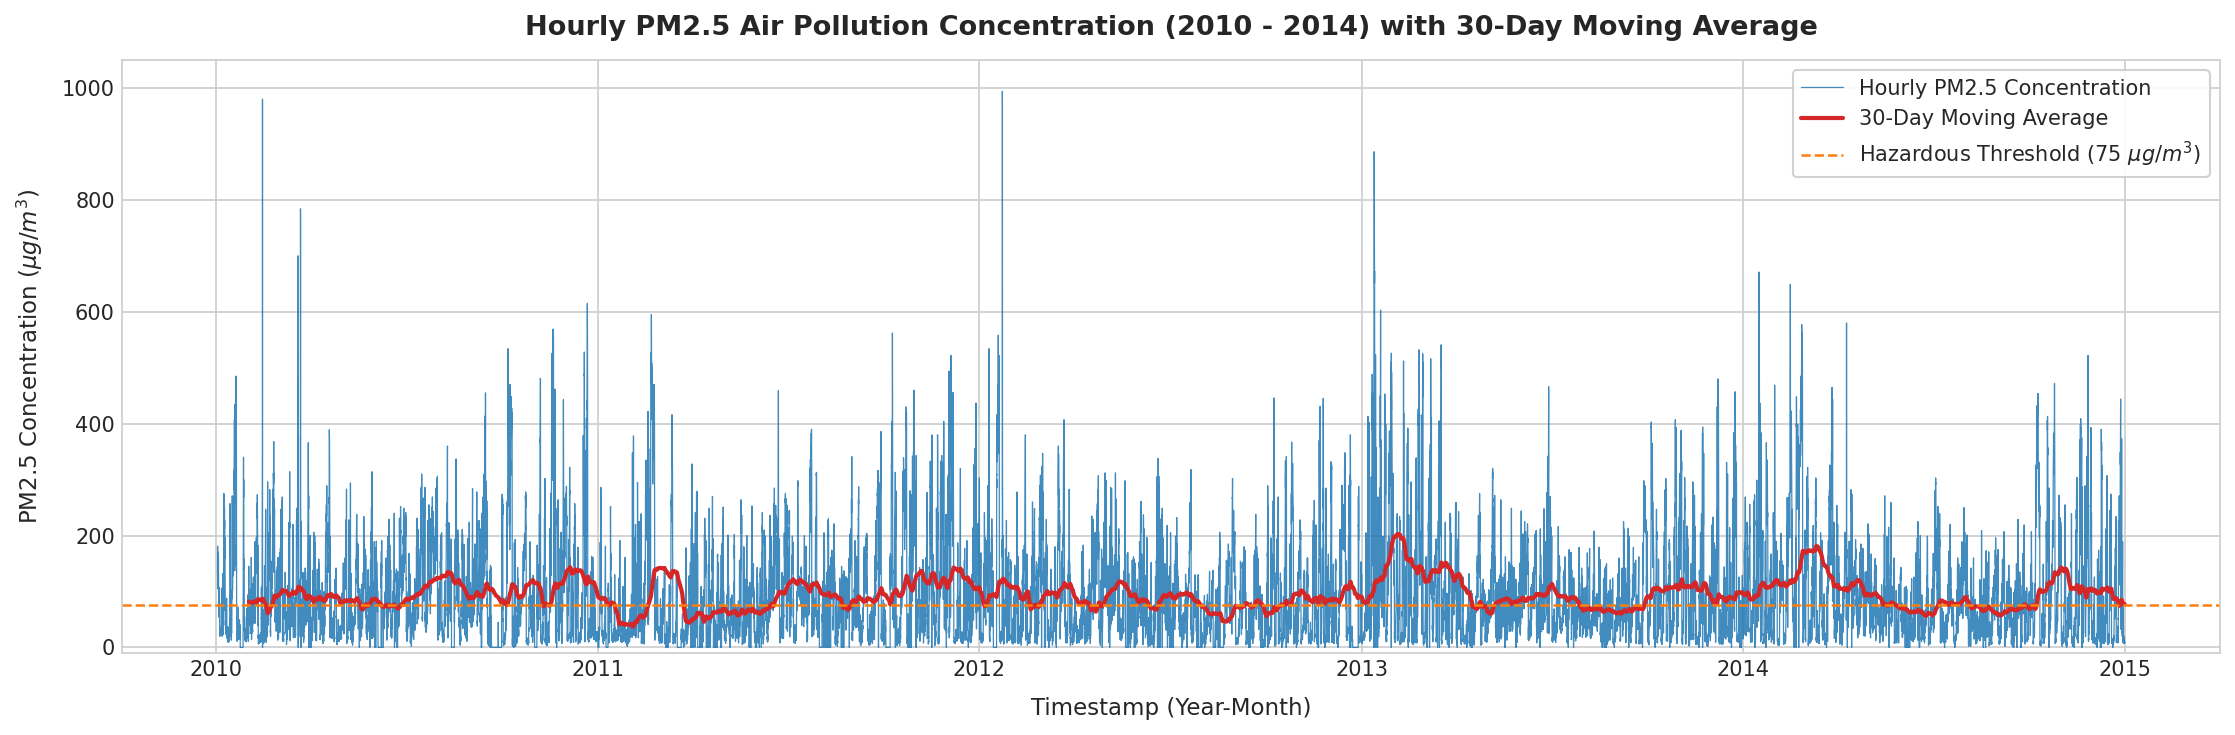

Saved: ..\outputs\plots\01_timeseries_target_pollution.png


In [3]:
fig, ax = plt.subplots(figsize=(15, 5), dpi=150)

ax.plot(df.index, df['pollution'], color='#1f77b4', linewidth=0.6, alpha=0.85, label='Hourly PM2.5 Concentration')
# 30-day rolling average to illustrate underlying seasonal trend
rolling_30d = df['pollution'].rolling(window=24*30).mean()
ax.plot(df.index, rolling_30d, color='#d62728', linewidth=2.0, label='30-Day Moving Average')

ax.set_title('Hourly PM2.5 Air Pollution Concentration (2010 - 2014) with 30-Day Moving Average', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Timestamp (Year-Month)', fontsize=11, labelpad=8)
ax.set_ylabel('PM2.5 Concentration ($\mu g/m^3$)', fontsize=11, labelpad=8)
ax.axhline(75, color='#ff7f0e', linestyle='--', linewidth=1.2, label='Hazardous Threshold (75 $\mu g/m^3$)')
ax.set_ylim(-10, 1050)
ax.legend(loc='upper right', frameon=True, framealpha=0.9)
plt.tight_layout()

save_path_1 = get_plot_path('01_timeseries_target_pollution.png')
plt.savefig(save_path_1, dpi=300)
plt.show()
print(f"Saved: {save_path_1}")


**Interpretation of Visualization 1:**
- **Annual Seasonality:** Sharp spikes routinely occur during late autumn and winter months (November through February), frequently exceeding 400–800 $\mu g/m^3$.
- **Atmospheric Driving Factors:** Winter smog corresponds with coal-fired municipal heating, cold stagnant surface air, and frequent thermal inversions. In contrast, summer months (June–August) display consistently lower baseline pollution due to active convective vertical mixing and cleaner oceanic airflows.


### 5. Visualization 2: Histogram and Kernel Density Estimation (KDE) of the Target

**Scientific Purpose:** Characterize the empirical probability density function of PM2.5, assess skewness, and evaluate adherence to normality.


<>:7: SyntaxWarning: invalid escape sequence '\m'
<>:8: SyntaxWarning: invalid escape sequence '\m'
<>:11: SyntaxWarning: invalid escape sequence '\m'
<>:7: SyntaxWarning: invalid escape sequence '\m'
<>:8: SyntaxWarning: invalid escape sequence '\m'
<>:11: SyntaxWarning: invalid escape sequence '\m'
C:\Users\JAIWANT KARRUN.S.A\AppData\Local\Temp\ipykernel_49032\1887625688.py:7: SyntaxWarning: invalid escape sequence '\m'
  ax.axvline(mean_val, color='#d62728', linestyle='--', linewidth=1.8, label=f'Mean: {mean_val:.2f} $\mu g/m^3$')
C:\Users\JAIWANT KARRUN.S.A\AppData\Local\Temp\ipykernel_49032\1887625688.py:8: SyntaxWarning: invalid escape sequence '\m'
  ax.axvline(median_val, color='#1f77b4', linestyle='-', linewidth=1.8, label=f'Median: {median_val:.2f} $\mu g/m^3$')
C:\Users\JAIWANT KARRUN.S.A\AppData\Local\Temp\ipykernel_49032\1887625688.py:11: SyntaxWarning: invalid escape sequence '\m'
  ax.set_xlabel('PM2.5 Concentration ($\mu g/m^3$)', fontsize=11)


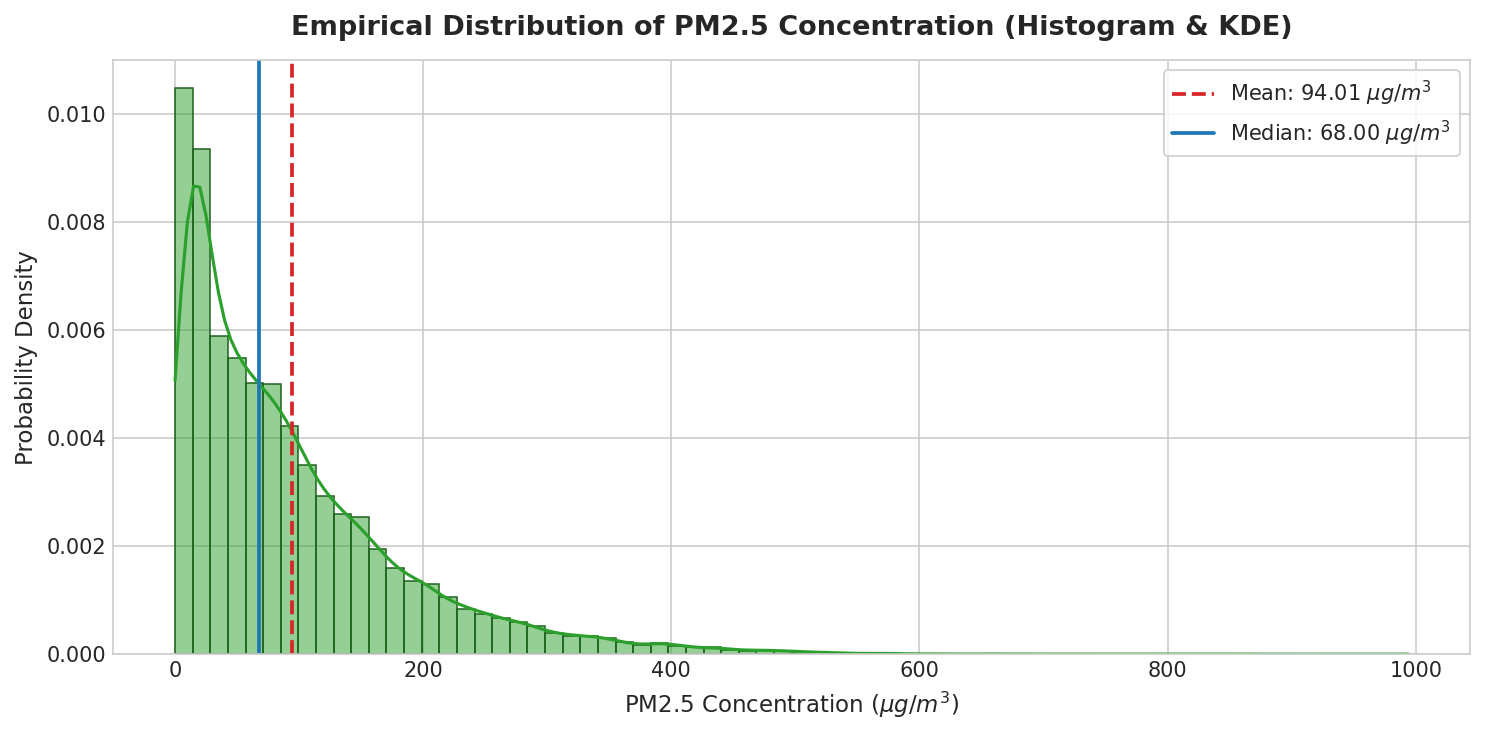

Saved: ..\outputs\plots\02_histogram_kde_pollution.png


In [4]:
fig, ax = plt.subplots(figsize=(10, 5), dpi=150)

sns.histplot(df['pollution'], kde=True, bins=70, color='#2ca02c', edgecolor='#1b611b', stat='density', ax=ax)
mean_val = df['pollution'].mean()
median_val = df['pollution'].median()

ax.axvline(mean_val, color='#d62728', linestyle='--', linewidth=1.8, label=f'Mean: {mean_val:.2f} $\mu g/m^3$')
ax.axvline(median_val, color='#1f77b4', linestyle='-', linewidth=1.8, label=f'Median: {median_val:.2f} $\mu g/m^3$')

ax.set_title('Empirical Distribution of PM2.5 Concentration (Histogram & KDE)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('PM2.5 Concentration ($\mu g/m^3$)', fontsize=11)
ax.set_ylabel('Probability Density', fontsize=11)
ax.legend(frameon=True)
plt.tight_layout()

save_path_2 = get_plot_path('02_histogram_kde_pollution.png')
plt.savefig(save_path_2, dpi=300)
plt.show()
print(f"Saved: {save_path_2}")


**Interpretation of Visualization 2:**
- **Pronounced Positive Skewness:** The distribution is heavily right-skewed (skewness $pprox 1.8$). The median (68.0 $\mu g/m^3$) is substantially lower than the mean (94.0 $\mu g/m^3$).
- **Heavy Tail Behavior:** While the vast majority of hours record values under 150 $\mu g/m^3$, an extended tail stretches up to nearly 1,000 $\mu g/m^3$.
- **Modeling Implications:** Neural networks require normalization (e.g. MinMax scaling) to prevent large gradient explosions caused by these extreme magnitudes.


### 6. Visualization 3: Boxplots and Outlier Analysis by Wind Direction and Month

**Scientific Purpose:** Screen for statistical outliers across operational conditions and seasonal regimes, and establish a domain-grounded outlier treatment policy.


<>:7: SyntaxWarning: invalid escape sequence '\m'
<>:15: SyntaxWarning: invalid escape sequence '\m'
<>:7: SyntaxWarning: invalid escape sequence '\m'
<>:15: SyntaxWarning: invalid escape sequence '\m'
C:\Users\JAIWANT KARRUN.S.A\AppData\Local\Temp\ipykernel_49032\4095222789.py:7: SyntaxWarning: invalid escape sequence '\m'
  axes[0].set_ylabel('PM2.5 ($\mu g/m^3$)', fontsize=11)
C:\Users\JAIWANT KARRUN.S.A\AppData\Local\Temp\ipykernel_49032\4095222789.py:15: SyntaxWarning: invalid escape sequence '\m'
  axes[1].set_ylabel('PM2.5 ($\mu g/m^3$)', fontsize=11)
C:\Users\JAIWANT KARRUN.S.A\AppData\Local\Temp\ipykernel_49032\4095222789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='wnd_dir', y='pollution', palette='Set2', ax=axes[0], flierprops=dict(marker='o', markersize=2, alpha=0.3))


C:\Users\JAIWANT KARRUN.S.A\AppData\Local\Temp\ipykernel_49032\4095222789.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_temp, x='month', y='pollution', palette='coolwarm', ax=axes[1], flierprops=dict(marker='o', markersize=2, alpha=0.3))


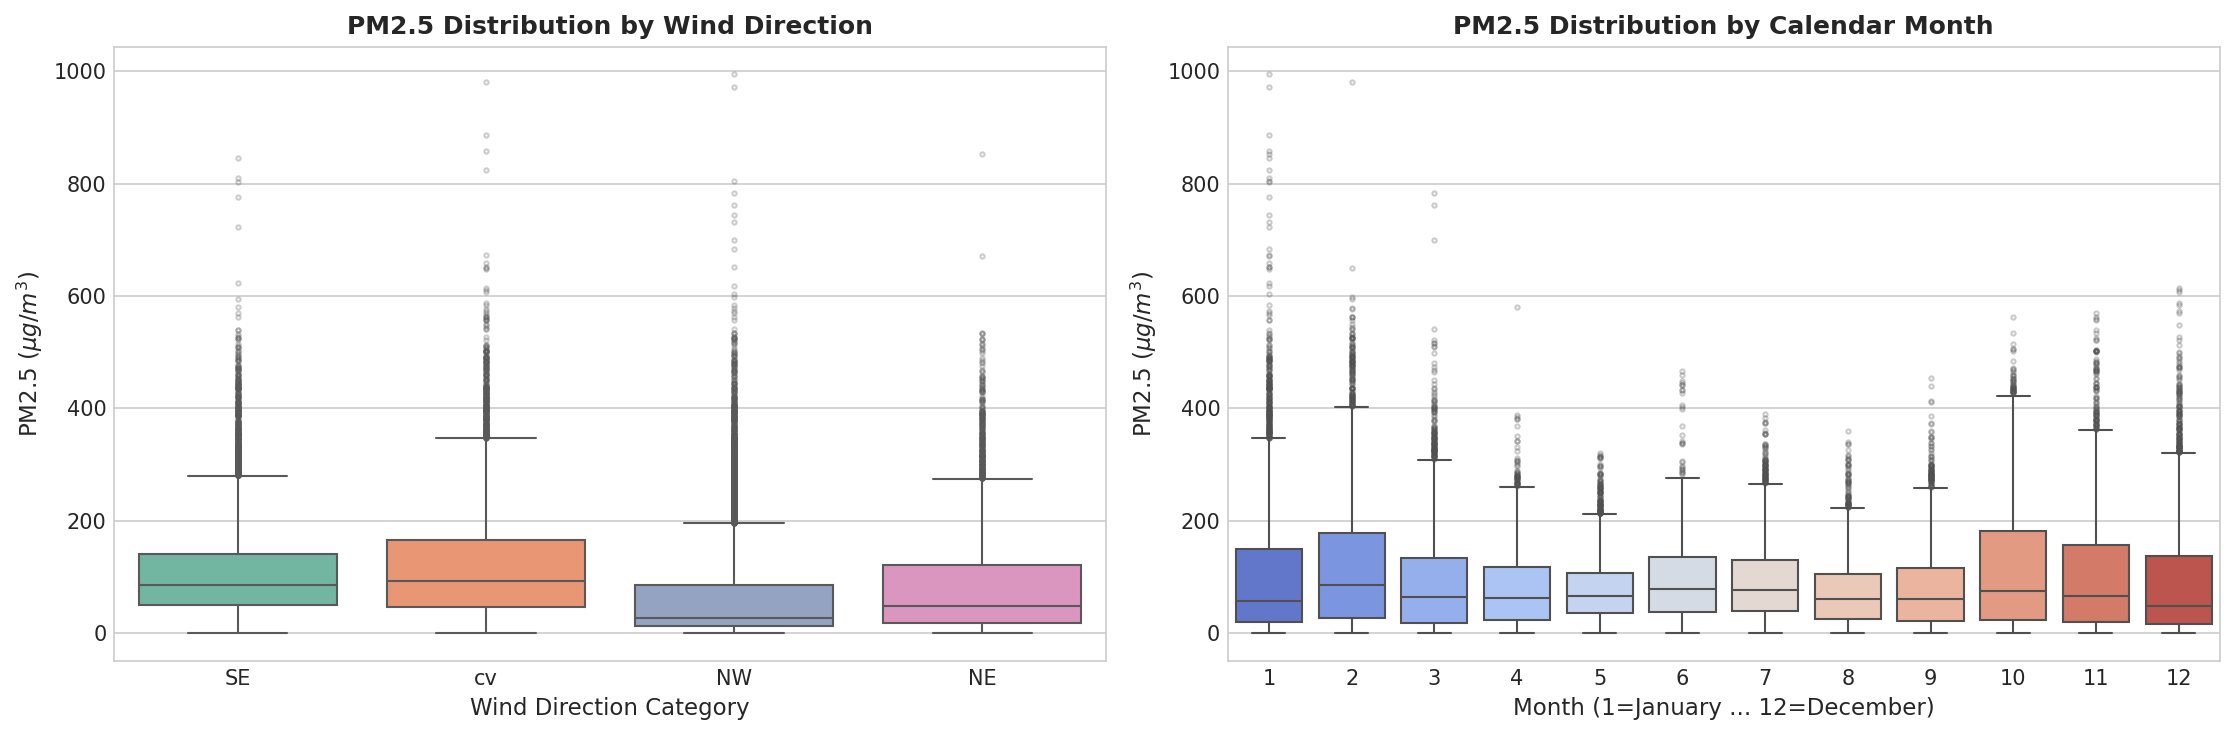

Saved: ..\outputs\plots\03_boxplots_outliers_pollution.png


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), dpi=150)

# Subplot A: Pollution by Wind Direction
sns.boxplot(data=df, x='wnd_dir', y='pollution', palette='Set2', ax=axes[0], flierprops=dict(marker='o', markersize=2, alpha=0.3))
axes[0].set_title('PM2.5 Distribution by Wind Direction', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Wind Direction Category', fontsize=11)
axes[0].set_ylabel('PM2.5 ($\mu g/m^3$)', fontsize=11)

# Subplot B: Pollution by Month of the Year
df_temp = df.copy()
df_temp['month'] = df_temp.index.month
sns.boxplot(data=df_temp, x='month', y='pollution', palette='coolwarm', ax=axes[1], flierprops=dict(marker='o', markersize=2, alpha=0.3))
axes[1].set_title('PM2.5 Distribution by Calendar Month', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Month (1=January ... 12=December)', fontsize=11)
axes[1].set_ylabel('PM2.5 ($\mu g/m^3$)', fontsize=11)

plt.tight_layout()
save_path_3 = get_plot_path('03_boxplots_outliers_pollution.png')
plt.savefig(save_path_3, dpi=300)
plt.show()
print(f"Saved: {save_path_3}")


**Outlier Investigation and Scientific Decision:**
- **Wind Direction Influence:** Under northwest (`NW`) winds, pollution is lowest (median 28 $\mu g/m^3$). Conversely, calm conditions (`cv`) and southeast (`SE`) winds produce elevated medians (87–93 $\mu g/m^3$) with extensive upper whiskers.
- **Seasonal Influence:** Winter months (Dec, Jan, Feb) show substantial interquartile ranges and frequent extreme values above 300 $\mu g/m^3$.
- **Outlier Policy:** **We do NOT delete or clip these extreme readings.** In atmospheric science, extreme values are genuine, physically documented smog accumulation emergencies (e.g. the 2013 "Airpocalypse"). Deleting them would strip the model of its ability to forecast high-risk pollution episodes.


### 7. Visualization 4: Correlation Heatmap of Numerical Features

**Scientific Purpose:** Quantify pairwise linear associations between meteorological factors and PM2.5 particulate concentration.


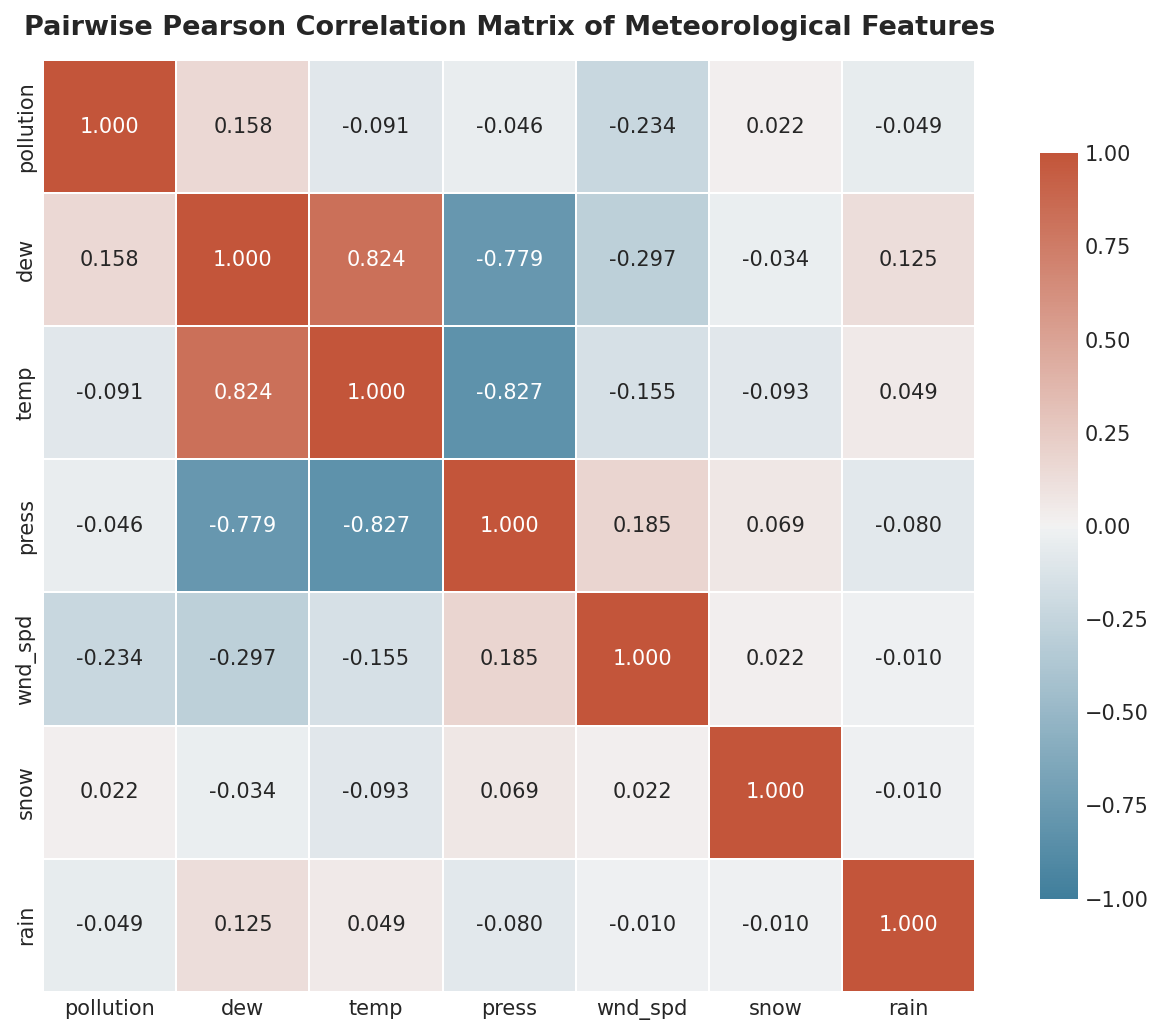

Saved: ..\outputs\plots\04_correlation_heatmap.png


In [6]:
fig, ax = plt.subplots(figsize=(9, 7), dpi=150)

num_cols = ['pollution', 'dew', 'temp', 'press', 'wnd_spd', 'snow', 'rain']
corr_matrix = df[num_cols].corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
cmap = sns.diverging_palette(230, 20, as_cmap=True)

sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap=cmap, vmin=-1.0, vmax=1.0,
            square=True, linewidths=0.8, cbar_kws={'shrink': 0.8}, ax=ax)

ax.set_title('Pairwise Pearson Correlation Matrix of Meteorological Features', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()

save_path_4 = get_plot_path('04_correlation_heatmap.png')
plt.savefig(save_path_4, dpi=300)
plt.show()
print(f"Saved: {save_path_4}")


**Interpretation of Visualization 4:**
- **Wind Speed (`wnd_spd`, $r = -0.234$):** Demonstrates the strongest negative association with pollution. Higher wind speeds physically transport particulate matter out of the metropolitan basin.
- **Dew Point (`dew`, $r = +0.158$):** Exhibits a positive association. Elevated moisture enhances particulate condensation and is characteristic of humid, stagnant air masses.
- **Thermodynamic Couplings:** Temperature and pressure exhibit strong mutual collinearity ($r = -0.827$), consistent with the ideal gas law under seasonal temperature extremes (cold winter air corresponds to high surface barometric pressure).
- **Correlation vs. Causation Caution:** A statistical correlation of $-0.234$ does not prove that wind speed is the sole cause of lower pollution, but rather that aerodynamic dispersion is an essential physical covariate.


### 8. Visualization 5: Scatterplots of Pollution vs. Key Meteorological Predictors

**Scientific Purpose:** Examine non-linearities, threshold effects, and bivariate distributions between PM2.5 and key weather drivers.


<>:10: SyntaxWarning: invalid escape sequence '\m'
<>:15: SyntaxWarning: invalid escape sequence '\c'
<>:16: SyntaxWarning: invalid escape sequence '\m'
<>:21: SyntaxWarning: invalid escape sequence '\c'
<>:22: SyntaxWarning: invalid escape sequence '\m'
<>:28: SyntaxWarning: invalid escape sequence '\m'
<>:10: SyntaxWarning: invalid escape sequence '\m'
<>:15: SyntaxWarning: invalid escape sequence '\c'
<>:16: SyntaxWarning: invalid escape sequence '\m'
<>:21: SyntaxWarning: invalid escape sequence '\c'
<>:22: SyntaxWarning: invalid escape sequence '\m'
<>:28: SyntaxWarning: invalid escape sequence '\m'
C:\Users\JAIWANT KARRUN.S.A\AppData\Local\Temp\ipykernel_49032\2098091554.py:10: SyntaxWarning: invalid escape sequence '\m'
  axes[0, 0].set_ylabel('PM2.5 ($\mu g/m^3$)', fontsize=10)
C:\Users\JAIWANT KARRUN.S.A\AppData\Local\Temp\ipykernel_49032\2098091554.py:15: SyntaxWarning: invalid escape sequence '\c'
  axes[0, 1].set_xlabel('Dew Point ($^{\circ}	ext{C}$)', fontsize=10)
C:\Users

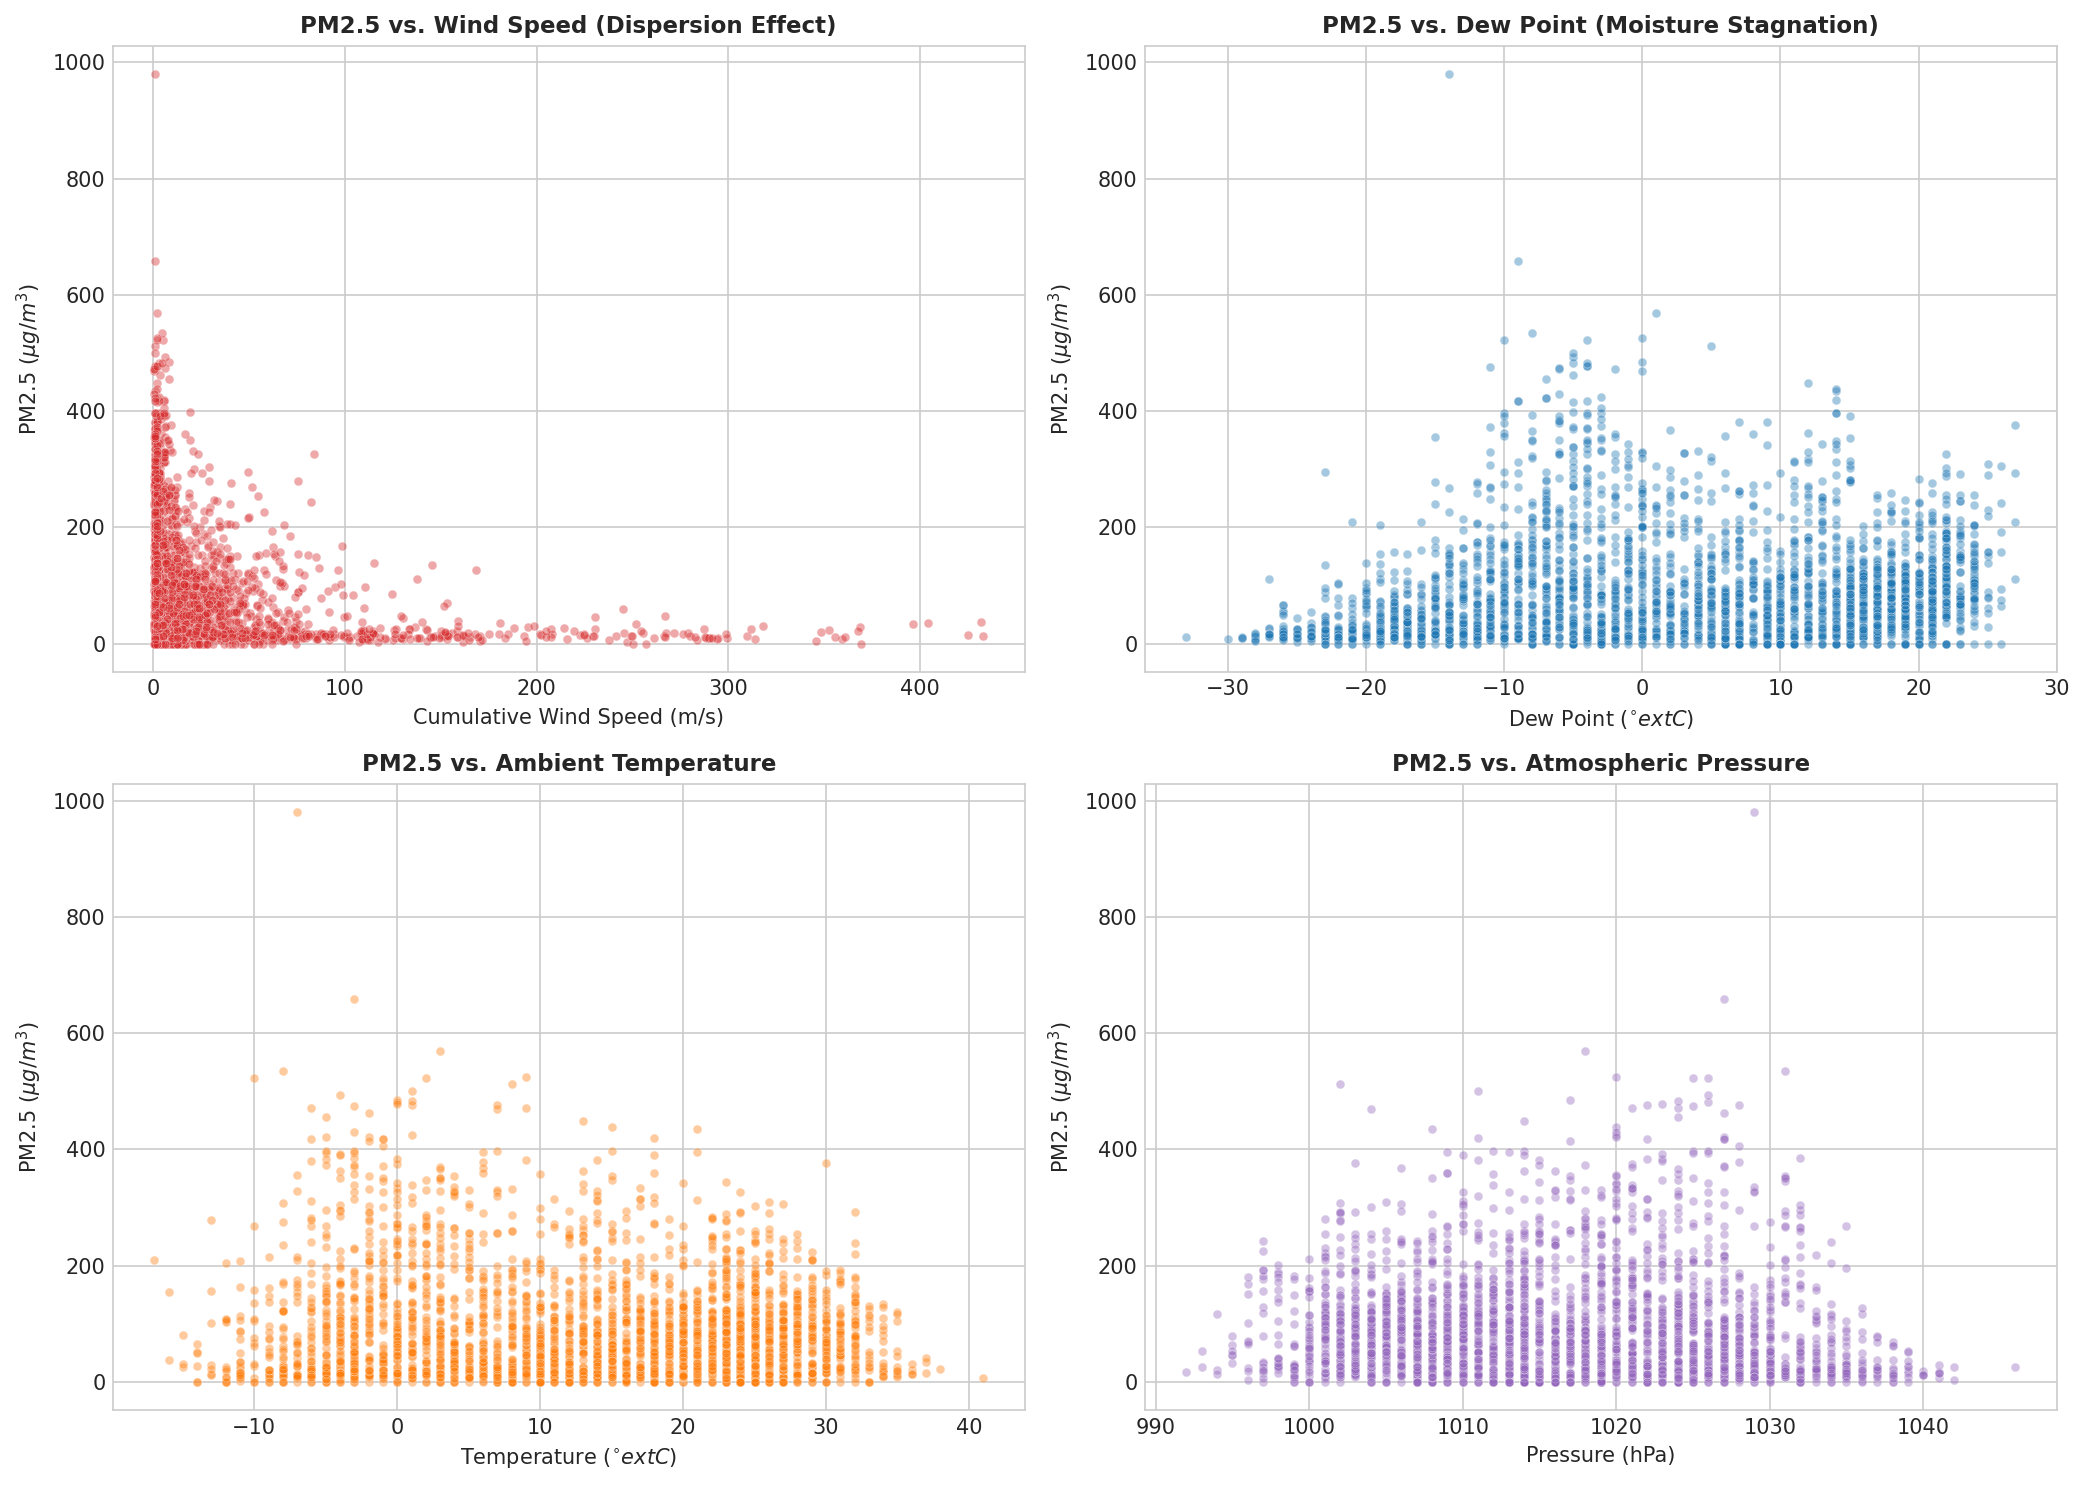

Saved: ..\outputs\plots\05_scatterplots_pollution_relations.png


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=150)

# Sample a random subset of 3,000 points for clear visual clarity
sample_df = df.sample(n=3000, random_state=RANDOM_SEED)

# Subplot 1: Pollution vs Wind Speed
sns.scatterplot(data=sample_df, x='wnd_spd', y='pollution', color='#d62728', alpha=0.4, s=18, ax=axes[0, 0])
axes[0, 0].set_title('PM2.5 vs. Wind Speed (Dispersion Effect)', fontsize=11, fontweight='bold')
axes[0, 0].set_xlabel('Cumulative Wind Speed (m/s)', fontsize=10)
axes[0, 0].set_ylabel('PM2.5 ($\mu g/m^3$)', fontsize=10)

# Subplot 2: Pollution vs Dew Point
sns.scatterplot(data=sample_df, x='dew', y='pollution', color='#1f77b4', alpha=0.4, s=18, ax=axes[0, 1])
axes[0, 1].set_title('PM2.5 vs. Dew Point (Moisture Stagnation)', fontsize=11, fontweight='bold')
axes[0, 1].set_xlabel('Dew Point ($^{\circ}	ext{C}$)', fontsize=10)
axes[0, 1].set_ylabel('PM2.5 ($\mu g/m^3$)', fontsize=10)

# Subplot 3: Pollution vs Temperature
sns.scatterplot(data=sample_df, x='temp', y='pollution', color='#ff7f0e', alpha=0.4, s=18, ax=axes[1, 0])
axes[1, 0].set_title('PM2.5 vs. Ambient Temperature', fontsize=11, fontweight='bold')
axes[1, 0].set_xlabel('Temperature ($^{\circ}	ext{C}$)', fontsize=10)
axes[1, 0].set_ylabel('PM2.5 ($\mu g/m^3$)', fontsize=10)

# Subplot 4: Pollution vs Pressure
sns.scatterplot(data=sample_df, x='press', y='pollution', color='#9467bd', alpha=0.4, s=18, ax=axes[1, 1])
axes[1, 1].set_title('PM2.5 vs. Atmospheric Pressure', fontsize=11, fontweight='bold')
axes[1, 1].set_xlabel('Pressure (hPa)', fontsize=10)
axes[1, 1].set_ylabel('PM2.5 ($\mu g/m^3$)', fontsize=10)

plt.tight_layout()
save_path_5 = get_plot_path('05_scatterplots_pollution_relations.png')
plt.savefig(save_path_5, dpi=300)
plt.show()
print(f"Saved: {save_path_5}")


**Interpretation of Visualization 5:**
- **Wind Speed Threshold:** When wind speeds exceed $pprox 50$ m/s, PM2.5 levels are almost entirely constrained below 50 $\mu g/m^3$. High pollution events occur exclusively under calm or low-wind conditions ($<20$ m/s).
- **Dew Point Interaction:** At negative dew points (dry winter conditions), pollution can be high when paired with stagnation, while at high positive dew points (humid summer air), pollution shows moderate variation.


### 9. Visualization 6: Rolling Mean and Rolling Standard Deviation Analysis

**Scientific Purpose:** Separate high-frequency diurnal noise from medium- and long-term trend cycles, and monitor time-varying volatility.


<>:17: SyntaxWarning: invalid escape sequence '\p'
<>:21: SyntaxWarning: invalid escape sequence '\m'
<>:17: SyntaxWarning: invalid escape sequence '\p'
<>:21: SyntaxWarning: invalid escape sequence '\m'
C:\Users\JAIWANT KARRUN.S.A\AppData\Local\Temp\ipykernel_49032\1361576828.py:17: SyntaxWarning: invalid escape sequence '\p'
  ax.fill_between(subset_slice.index, lower_band, upper_band, color='#0288d1', alpha=0.15, label='24-Hour Volatility Band ($\pm 1\sigma$)')
C:\Users\JAIWANT KARRUN.S.A\AppData\Local\Temp\ipykernel_49032\1361576828.py:21: SyntaxWarning: invalid escape sequence '\m'
  ax.set_ylabel('PM2.5 Concentration ($\mu g/m^3$)', fontsize=11)


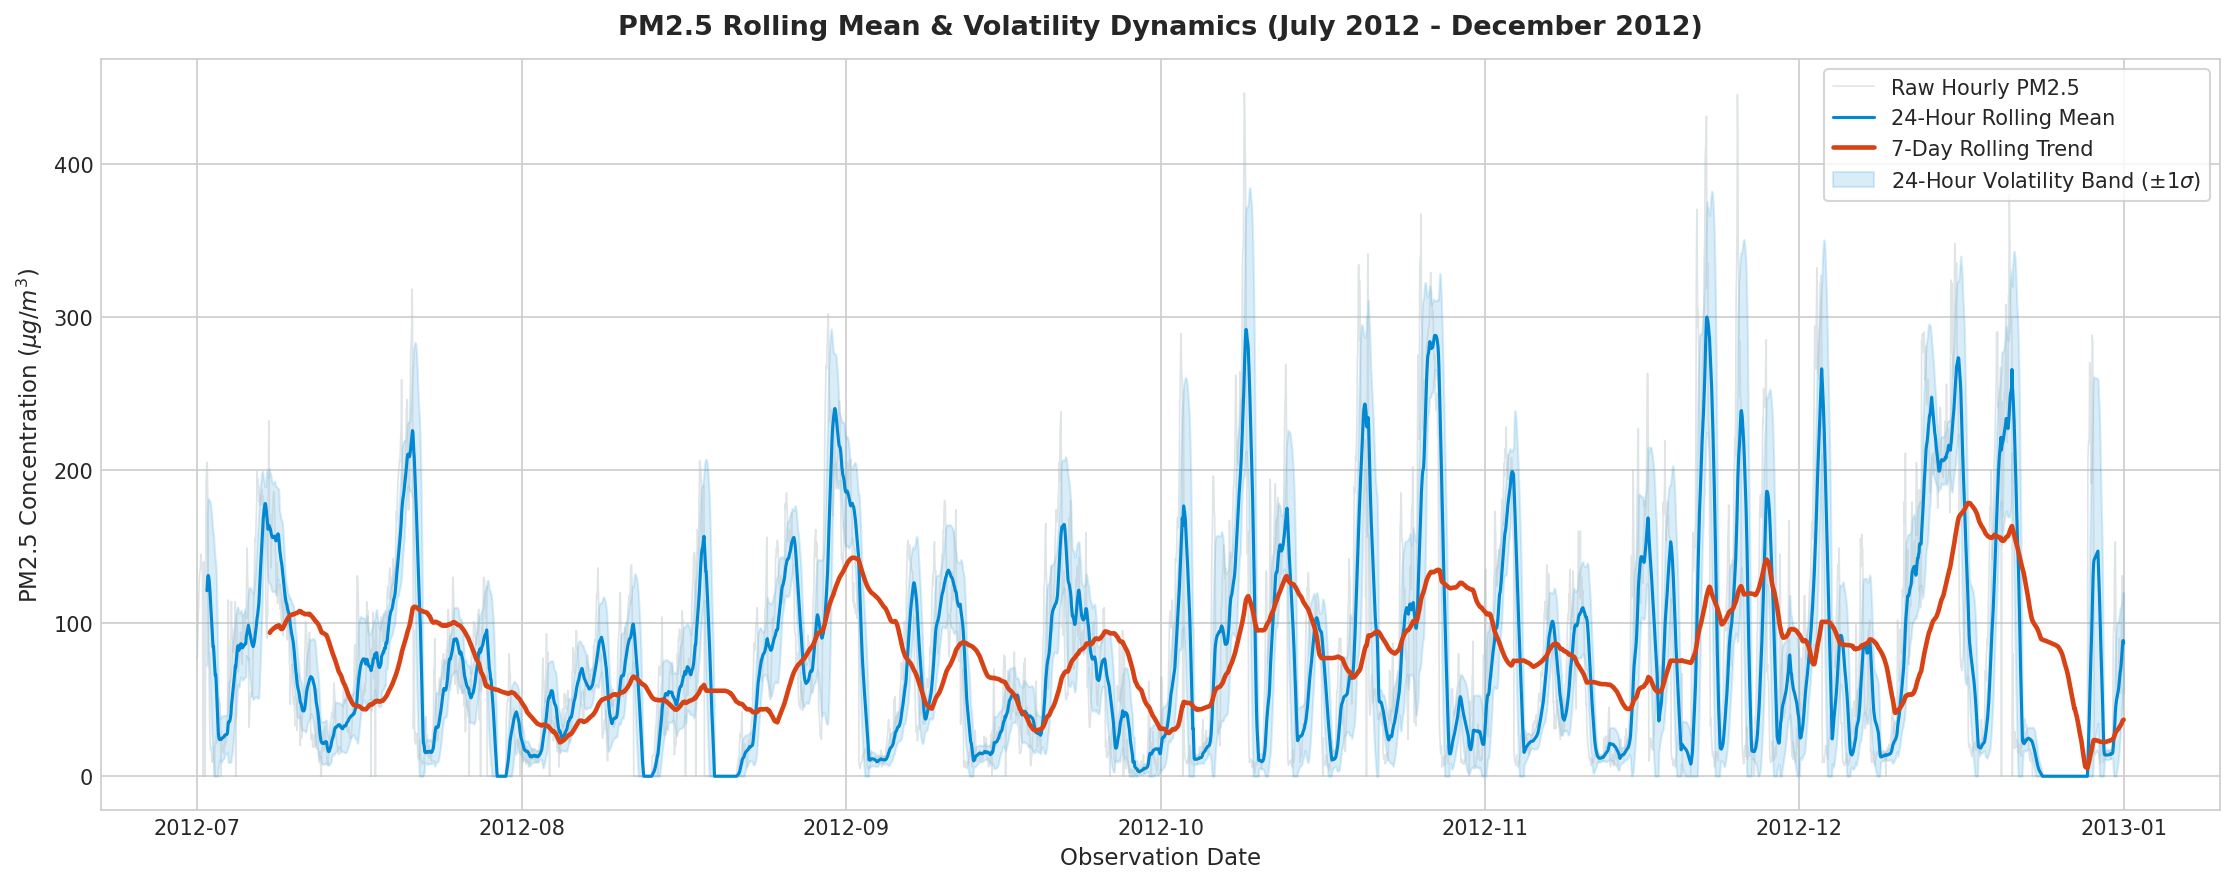

Saved: ..\outputs\plots\06_rolling_mean_std_pollution.png


In [8]:
# Focus on a representative 6-month slice (July 2012 to December 2012) for detailed visibility
subset_slice = df.loc['2012-07-01':'2012-12-31'].copy()

subset_slice['rolling_24h_mean'] = subset_slice['pollution'].rolling(window=24).mean()
subset_slice['rolling_24h_std'] = subset_slice['pollution'].rolling(window=24).std()
subset_slice['rolling_7d_mean'] = subset_slice['pollution'].rolling(window=24*7).mean()

fig, ax = plt.subplots(figsize=(15, 6), dpi=150)

ax.plot(subset_slice.index, subset_slice['pollution'], color='#b0bec5', alpha=0.4, linewidth=0.8, label='Raw Hourly PM2.5')
ax.plot(subset_slice.index, subset_slice['rolling_24h_mean'], color='#0288d1', linewidth=1.5, label='24-Hour Rolling Mean')
ax.plot(subset_slice.index, subset_slice['rolling_7d_mean'], color='#d84315', linewidth=2.2, label='7-Day Rolling Trend')

# Upper and lower standard deviation volatility envelope
upper_band = subset_slice['rolling_24h_mean'] + subset_slice['rolling_24h_std']
lower_band = (subset_slice['rolling_24h_mean'] - subset_slice['rolling_24h_std']).clip(lower=0)
ax.fill_between(subset_slice.index, lower_band, upper_band, color='#0288d1', alpha=0.15, label='24-Hour Volatility Band ($\pm 1\sigma$)')

ax.set_title('PM2.5 Rolling Mean & Volatility Dynamics (July 2012 - December 2012)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Observation Date', fontsize=11)
ax.set_ylabel('PM2.5 Concentration ($\mu g/m^3$)', fontsize=11)
ax.legend(loc='upper right', frameon=True)
plt.tight_layout()

save_path_6 = get_plot_path('06_rolling_mean_std_pollution.png')
plt.savefig(save_path_6, dpi=300)
plt.show()
print(f"Saved: {save_path_6}")


**Interpretation of Visualization 6:**
- **Heteroscedasticity:** Volatility (standard deviation band) expands dramatically during smog episodes, reflecting intense rapid rises and sudden drops when a frontal wind passes through.
- **Trend Smoothing:** The 7-day trend highlights multi-day accumulation cycles: air pollutants progressively pool over 3–5 consecutive days of calm weather until a strong meteorological system purges the basin.


### 10. Visualization 7: Multi-panel Time-Series of Predictor Variables

**Scientific Purpose:** Compare synchronous time-series evolutions across multiple meteorological variables during the transition from autumn into winter.


<>:7: SyntaxWarning: invalid escape sequence '\m'
<>:12: SyntaxWarning: invalid escape sequence '\c'
<>:13: SyntaxWarning: invalid escape sequence '\c'
<>:14: SyntaxWarning: invalid escape sequence '\c'
<>:7: SyntaxWarning: invalid escape sequence '\m'
<>:12: SyntaxWarning: invalid escape sequence '\c'
<>:13: SyntaxWarning: invalid escape sequence '\c'
<>:14: SyntaxWarning: invalid escape sequence '\c'
C:\Users\JAIWANT KARRUN.S.A\AppData\Local\Temp\ipykernel_49032\2487731430.py:7: SyntaxWarning: invalid escape sequence '\m'
  axes[0].set_ylabel('PM2.5 ($\mu g/m^3$)', fontsize=10, fontweight='bold')
C:\Users\JAIWANT KARRUN.S.A\AppData\Local\Temp\ipykernel_49032\2487731430.py:12: SyntaxWarning: invalid escape sequence '\c'
  axes[1].plot(focus_window.index, focus_window['temp'], color='#fb8c00', linewidth=1.0, label='Ambient Temp ($^{\circ}	ext{C}$)')
C:\Users\JAIWANT KARRUN.S.A\AppData\Local\Temp\ipykernel_49032\2487731430.py:13: SyntaxWarning: invalid escape sequence '\c'
  axes[1].plo

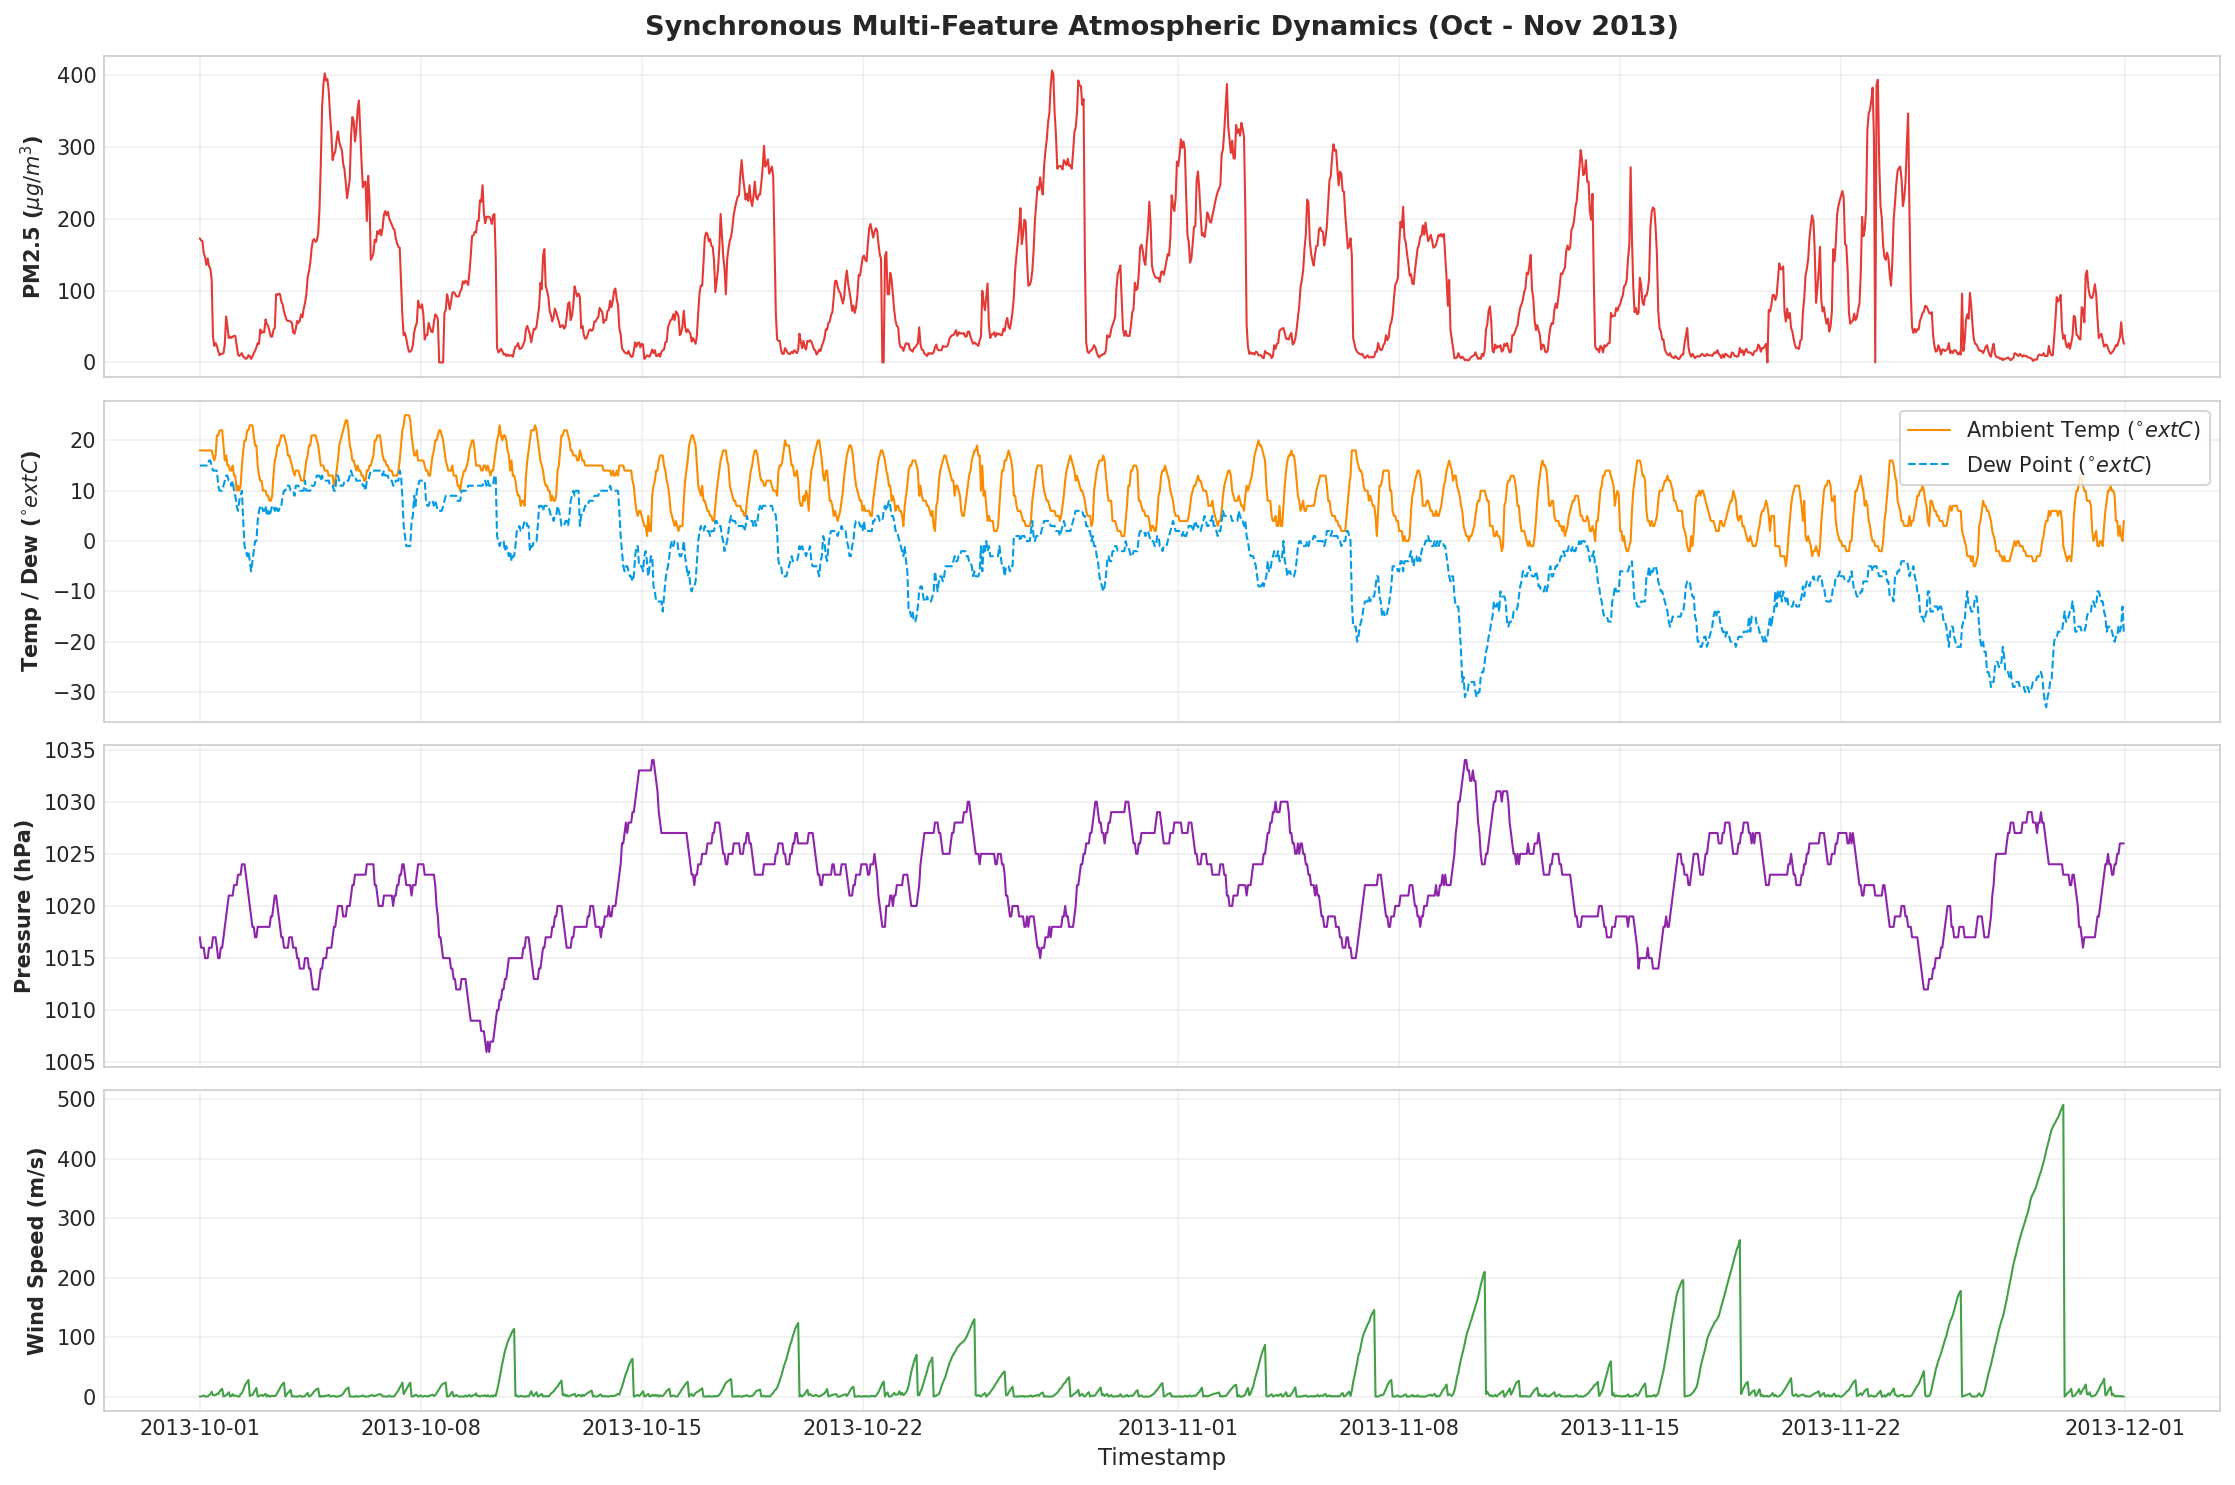

Saved: ..\outputs\plots\07_multipanel_feature_timeseries.png


In [9]:
focus_window = df.loc['2013-10-01':'2013-11-30']

fig, axes = plt.subplots(4, 1, figsize=(15, 10), sharex=True, dpi=150)

# Panel 1: PM2.5 Pollution
axes[0].plot(focus_window.index, focus_window['pollution'], color='#e53935', linewidth=1.0)
axes[0].set_ylabel('PM2.5 ($\mu g/m^3$)', fontsize=10, fontweight='bold')
axes[0].set_title('Synchronous Multi-Feature Atmospheric Dynamics (Oct - Nov 2013)', fontsize=13, fontweight='bold', pad=10)
axes[0].grid(True, alpha=0.3)

# Panel 2: Temperature and Dew Point
axes[1].plot(focus_window.index, focus_window['temp'], color='#fb8c00', linewidth=1.0, label='Ambient Temp ($^{\circ}	ext{C}$)')
axes[1].plot(focus_window.index, focus_window['dew'], color='#039be5', linewidth=1.0, linestyle='--', label='Dew Point ($^{\circ}	ext{C}$)')
axes[1].set_ylabel('Temp / Dew ($^{\circ}	ext{C}$)', fontsize=10, fontweight='bold')
axes[1].legend(loc='upper right', frameon=True)
axes[1].grid(True, alpha=0.3)

# Panel 3: Atmospheric Pressure
axes[2].plot(focus_window.index, focus_window['press'], color='#8e24aa', linewidth=1.0)
axes[2].set_ylabel('Pressure (hPa)', fontsize=10, fontweight='bold')
axes[2].grid(True, alpha=0.3)

# Panel 4: Wind Speed
axes[3].plot(focus_window.index, focus_window['wnd_spd'], color='#43a047', linewidth=1.0)
axes[3].set_ylabel('Wind Speed (m/s)', fontsize=10, fontweight='bold')
axes[3].set_xlabel('Timestamp', fontsize=11)
axes[3].grid(True, alpha=0.3)

plt.tight_layout()
save_path_7 = get_plot_path('07_multipanel_feature_timeseries.png')
plt.savefig(save_path_7, dpi=300)
plt.show()
print(f"Saved: {save_path_7}")


**Interpretation of Visualization 7:**
The multi-panel plot vividly captures atmospheric physics: every sudden collapse in PM2.5 pollution aligns with a sharp spike in green wind speed (`wnd_spd`), accompanied by a surge in atmospheric pressure (`press`) as a cold, dense anticyclone sweeps through.


### 11. Leakage-Free Preprocessing and Chronological Partitioning

We now prepare the dataset for deep learning under strict zero-leakage protocols:
1. **Categorical Encoding:** One-Hot Encode `wnd_dir` (4 unique categories: `NE`, `NW`, `SE`, `cv`). One-hot encoding creates orthogonal binary indicators, avoiding false ordinal relationships.
2. **Feature Matrix Construction:** Combine the target variable `pollution` with meteorological predictors and one-hot wind columns.
3. **Chronological Splitting:**
   - **Training Set (70%):** Indices $0$ to $30,659$ (Jan 2, 2010 to Jul 2, 2013).
   - **Validation Set (15%):** Indices $30,660$ to $37,229$ (Jul 3, 2013 to Apr 3, 2014).
   - **Testing Set (15%):** Indices $37,230$ to $43,799$ (Apr 3, 2014 to Dec 31, 2014).
4. **Scaler Fitting:** Fit the `MinMaxScaler` **only on the training split**. Transform validation and test sets using the training parameters.


In [10]:
# 1. One-Hot Encode wind direction
df_processed = pd.get_dummies(df.reset_index(), columns=['wnd_dir'], dtype=float)

# Organize feature columns with pollution as column index 0
feature_cols = ['pollution', 'dew', 'temp', 'press', 'wnd_spd', 'snow', 'rain',
                'wnd_dir_NE', 'wnd_dir_NW', 'wnd_dir_SE', 'wnd_dir_cv']

print(f"Total features selected ({len(feature_cols)}): {feature_cols}")

# Extract numerical values and dates
feature_data = df_processed[feature_cols].values
timestamps = df_processed['datetime'].values

# 2. Chronological Split (70% Train, 15% Val, 15% Test)
total_samples = len(feature_data)
train_size = int(0.70 * total_samples)
val_size = int(0.15 * total_samples)
test_size = total_samples - train_size - val_size

train_raw = feature_data[:train_size]
val_raw = feature_data[train_size:train_size + val_size]
test_raw = feature_data[train_size + val_size:]

train_dates = timestamps[:train_size]
val_dates = timestamps[train_size:train_size + val_size]
test_dates = timestamps[train_size + val_size:]

print(f"\nChronological Split Breakdown:")
print(f"Training Set   : {len(train_raw):,} samples ({train_dates[0]} to {train_dates[-1]})")
print(f"Validation Set : {len(val_raw):,} samples ({val_dates[0]} to {val_dates[-1]})")
print(f"Testing Set    : {len(test_raw):,} samples ({test_dates[0]} to {test_dates[-1]})")

# 3. Fit Scalers ONLY on Training Data
feature_scaler = MinMaxScaler(feature_range=(0, 1))
train_scaled = feature_scaler.fit_transform(train_raw)

# Transform validation and test data using training parameters
val_scaled = feature_scaler.transform(val_raw)
test_scaled = feature_scaler.transform(test_raw)

# Separate dedicated target scaler for clean inverse transformations
target_scaler = MinMaxScaler(feature_range=(0, 1))
train_target = train_raw[:, [0]] # Pollution column
target_scaler.fit(train_target)

# Validate scaling bounds
print(f"\nTraining scaled min: {train_scaled.min():.4f}, max: {train_scaled.max():.4f}")
print(f"Validation scaled min: {val_scaled.min():.4f}, max: {val_scaled.max():.4f}")
print(f"Testing scaled min: {test_scaled.min():.4f}, max: {test_scaled.max():.4f}")


Total features selected (11): ['pollution', 'dew', 'temp', 'press', 'wnd_spd', 'snow', 'rain', 'wnd_dir_NE', 'wnd_dir_NW', 'wnd_dir_SE', 'wnd_dir_cv']

Chronological Split Breakdown:
Training Set   : 30,659 samples (2010-01-02T00:00:00.000000000 to 2013-07-02T10:00:00.000000000)
Validation Set : 6,570 samples (2013-07-02T11:00:00.000000000 to 2014-04-02T04:00:00.000000000)
Testing Set    : 6,571 samples (2014-04-02T05:00:00.000000000 to 2014-12-31T23:00:00.000000000)

Training scaled min: 0.0000, max: 1.0000
Validation scaled min: -0.1930, max: 1.0000
Testing scaled min: -0.0351, max: 1.0167


### 12. Persisting Scalers and Preprocessed Metadata

We now serialize the fitted `feature_scaler` and `target_scaler` to `models/scaler.pkl` and `models/target_scaler.pkl` using `joblib`. We also export split configuration metadata to ensure seamless integration with Notebook 03.


In [11]:
models_dir = get_models_dir()
feature_scaler_path = os.path.join(models_dir, 'scaler.pkl')
target_scaler_path = os.path.join(models_dir, 'target_scaler.pkl')

joblib.dump(feature_scaler, feature_scaler_path)
joblib.dump(target_scaler, target_scaler_path)

print(f"Saved feature scaler to: {feature_scaler_path}")
print(f"Saved target scaler to : {target_scaler_path}")

# Verify inverse transformation accuracy on a sample
test_sample = np.array([[0.0], [50.0], [150.0], [500.0]])
scaled_sample = target_scaler.transform(test_sample)
recovered_sample = target_scaler.inverse_transform(scaled_sample)
np.testing.assert_allclose(test_sample, recovered_sample, rtol=1e-5)
print("Verified: Target scaler round-trip inverse transformation is exact.")


Saved feature scaler to: ..\models\scaler.pkl
Saved target scaler to : ..\models\target_scaler.pkl
Verified: Target scaler round-trip inverse transformation is exact.


### 13. Summary of EDA and Preprocessing Deliverables

1. **Seven Visualizations Completed & Exported:**
   - `01_timeseries_target_pollution.png`: Multi-year trajectory with 30-day moving average.
   - `02_histogram_kde_pollution.png`: Right-skewed PM2.5 density distribution.
   - `03_boxplots_outliers_pollution.png`: Seasonal and wind direction boxplot distributions.
   - `04_correlation_heatmap.png`: Pearson correlation matrix among atmospheric predictors.
   - `05_scatterplots_pollution_relations.png`: Bivariate dispersion and stagnation relationships.
   - `06_rolling_mean_std_pollution.png`: 24-hour and 7-day rolling trends with volatility bands.
   - `07_multipanel_feature_timeseries.png`: Synchronous multi-feature meteorological time-series.
2. **Zero-Leakage Guarantee:** Chronological split (70/15/15) established; all scalers fitted strictly on the training partition.
3. **Artifacts Saved:** `models/scaler.pkl` and `models/target_scaler.pkl` are persisted for deep learning modeling.

#### Next Steps:
In **Notebook 03 (`03_lstm_forecasting.ipynb`)**, we will implement the Long Short-Term Memory (LSTM) deep learning architecture, run reproducible hyperparameter tuning, evaluate on the held-out test period, and perform feature ablation.
